In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv('E:\\Data Science\\Machine Learning\\data\\concrete_data.csv')

In [21]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [9]:
X, y = df.drop(columns = ['Strength']), df.iloc[:,-1]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.3)

In [12]:
lr = LinearRegression()

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

r2_score(y_test, y_pred)

0.5866481900599674

In [18]:
## cross validation score:
lr = LinearRegression()
np.mean(cross_val_score(lr, X, y , scoring= 'r2'))

np.float64(0.46099404916628683)

<Axes: xlabel='Cement', ylabel='Density'>

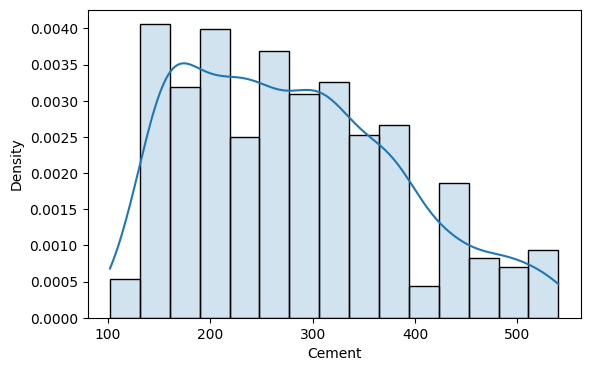

In [27]:
plt.figure(figsize= (14,4))
plt.subplot(121)
sns.histplot(X, x='Cement', stat= 'density', kde= True, alpha = 0.2)

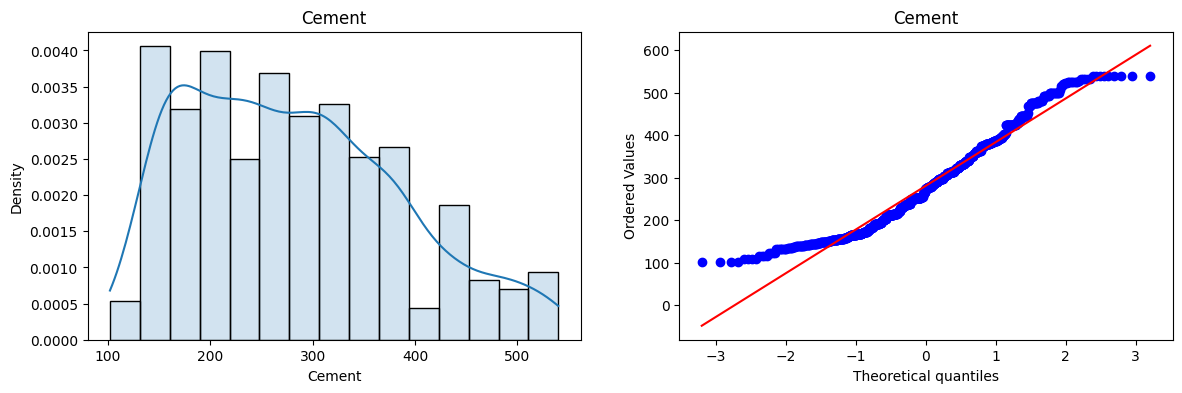

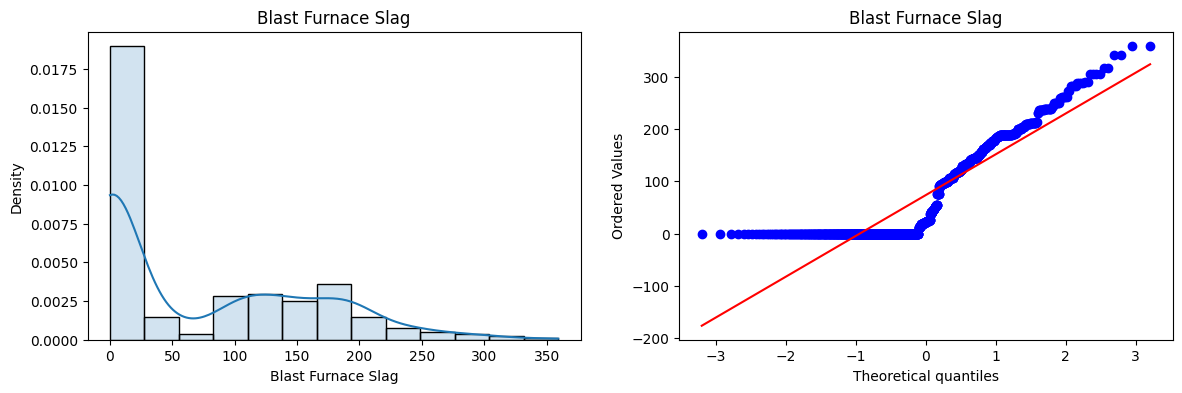

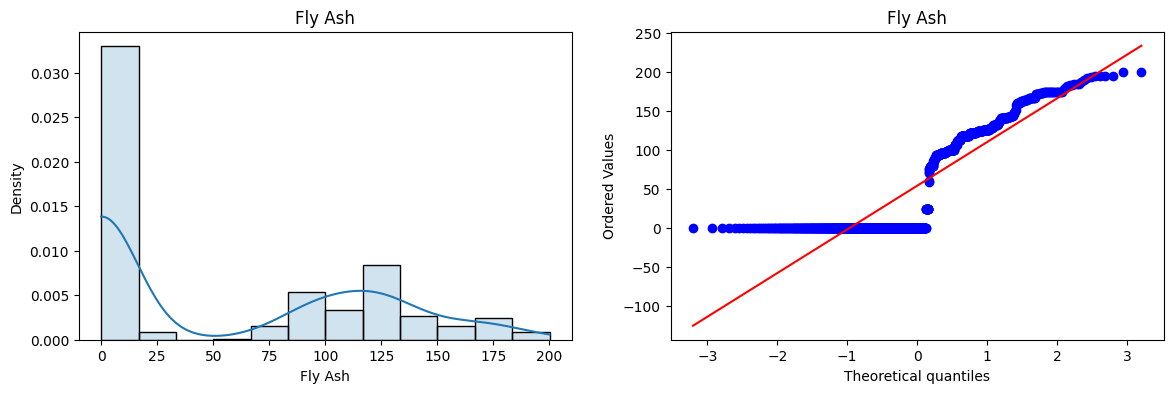

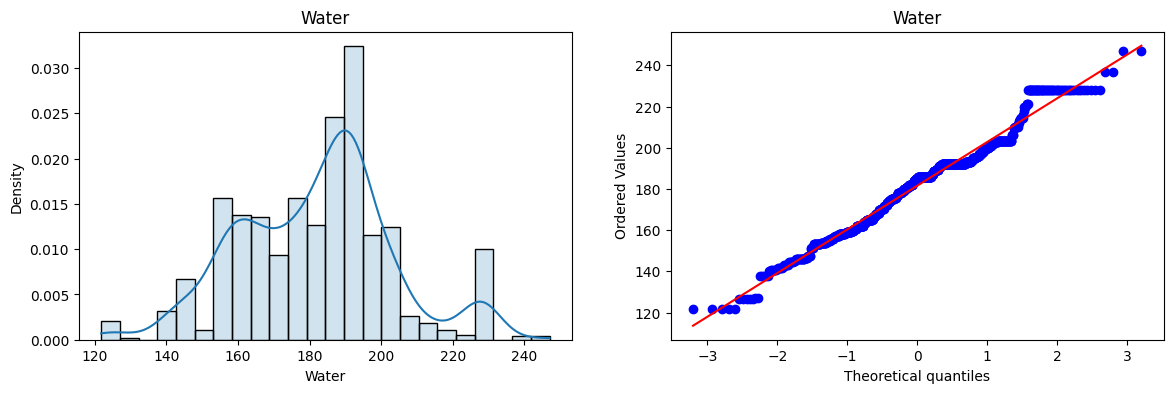

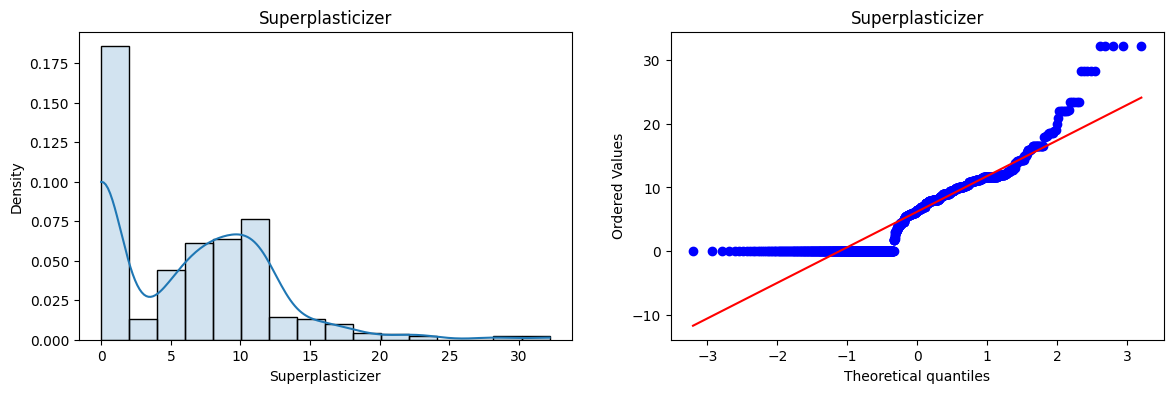

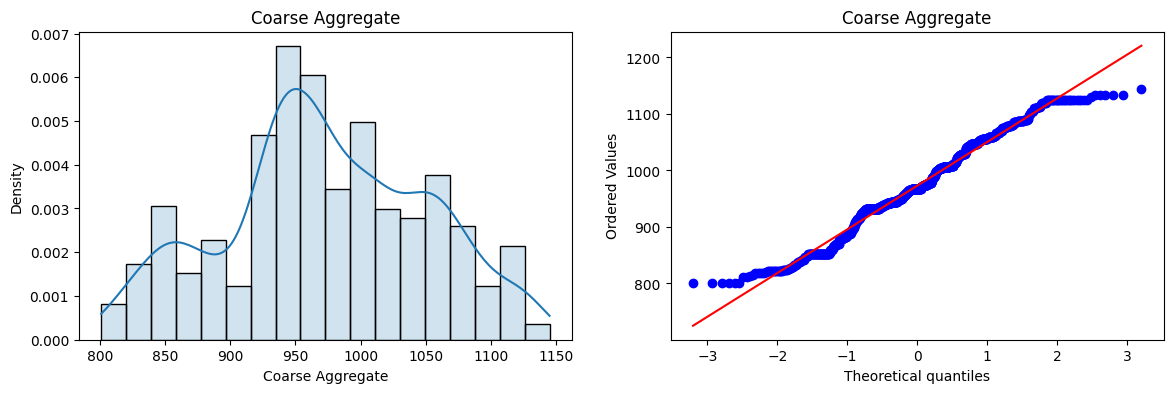

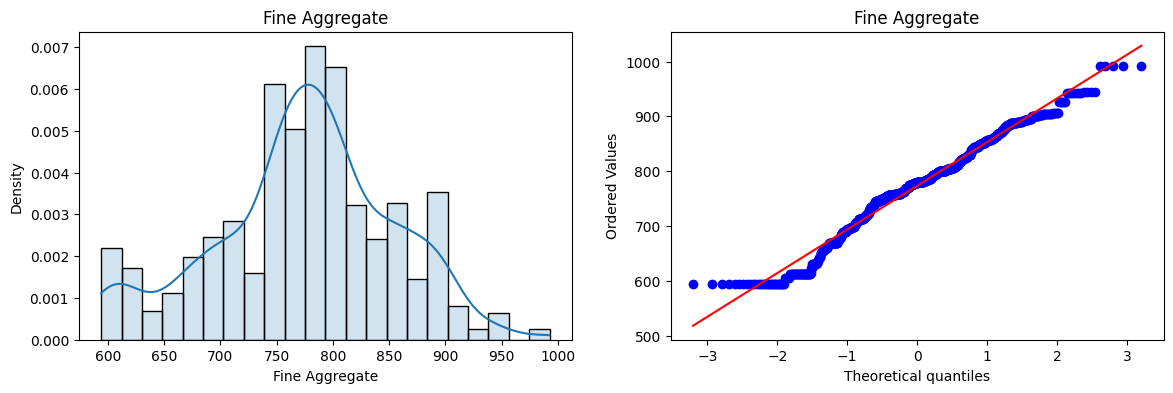

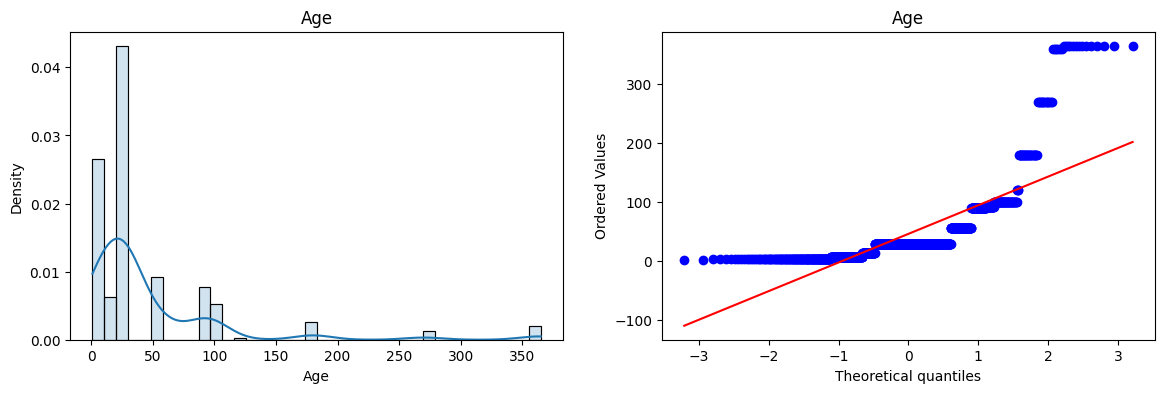

In [29]:
#### Plotting density and Q-Q plot for each variable:

for col in X.columns:
    plt.figure(figsize= (14,4))
    plt.subplot(121)
    sns.histplot(X, x= col, stat= 'density', kde= True, alpha = 0.2)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X[col], dist= 'norm', plot = plt)
    plt.title(col)

    plt.show()

In [30]:
### There are two types of power transfomer box-cox and yeo-jhonson. yeo-jhonson performs better hence it the default transformer.
pt = PowerTransformer()

X_train_transformed = pt.fit_transform(X_train)
X_test_transformed = pt.fit_transform(X_test)

lr = LinearRegression()

lr.fit(X_train_transformed, y_train)
y_pred2 = lr.predict(X_test_transformed)

r2_score(y_test, y_pred2)

0.8182375818490225

In [31]:
## cross validation score:
X_transformed = pt.fit_transform(X)

np.mean(cross_val_score(lr, X_transformed, y , scoring= 'r2'))

np.float64(0.6834625134285742)